<a href="https://colab.research.google.com/github/nickkraus52/MachineLearning/blob/main/HW6/faces_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Task 1: Dataset Loading and Dimensionality Inspection

In this code cell I imported my dataset and initialized the data I need to analyze my models. I then evaluated the dimensions and cycled through my subjects and printed each an image of each. Using np.where() I found one image from each subject and printed them using imshow().

Number of samples: 400
Unique subjects: 40
Image dimensions: 4096 - 64px x 64px


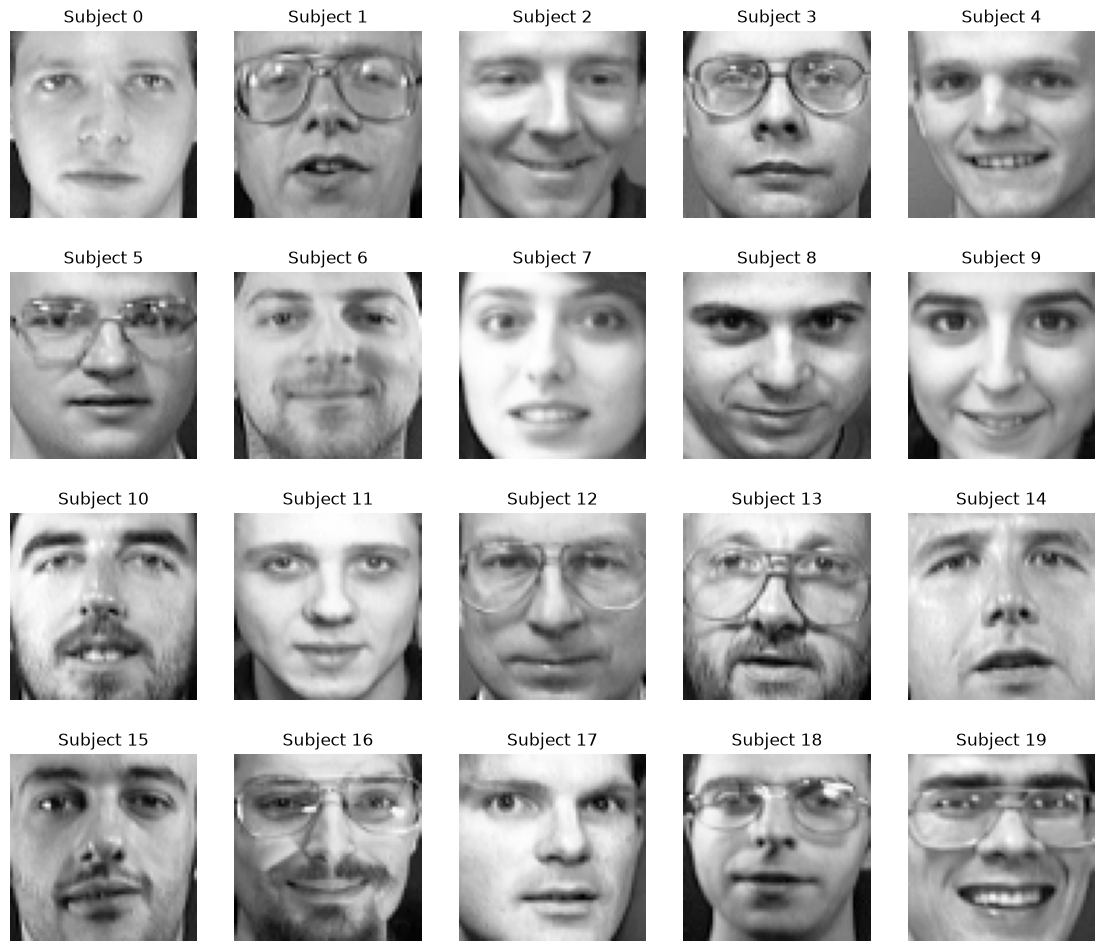

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_olivetti_faces
import matplotlib.pyplot as plt

faces = fetch_olivetti_faces(shuffle=False)
X = faces.data
y = faces.target
images = faces.images

X.shape
print(f'Number of samples: {X.shape[0]}')
print(f'Unique subjects: {len(np.unique(y))}')
print(f'Image dimensions: {X.shape[1]} - {images.shape[1]}px x {images.shape[2]}px')

fig, axes = plt.subplots(4, 5, figsize=(14, 12))
for ax, subject_id in zip(axes.ravel(), range(20) ):
    i = np.where(y == subject_id)[0][0]
    ax.imshow(images[i], cmap='gray')
    ax.set_title(f'Subject {subject_id}')
    ax.axis('off')

## Task 2: Cumulative Explained Variance & Elbow Plot

This cell fits a full PCA using the most amount of components available. I then access the explained_variance_ratio_ value to evaluate the ratio of variance tied to each component. I then plotted two plots one to display the individual explained variance of each component (elbow plot) and one to display the cumulative variance of the components. I then used np.argmax() to find the component amount for variances: 90%, 95%, and 99%.

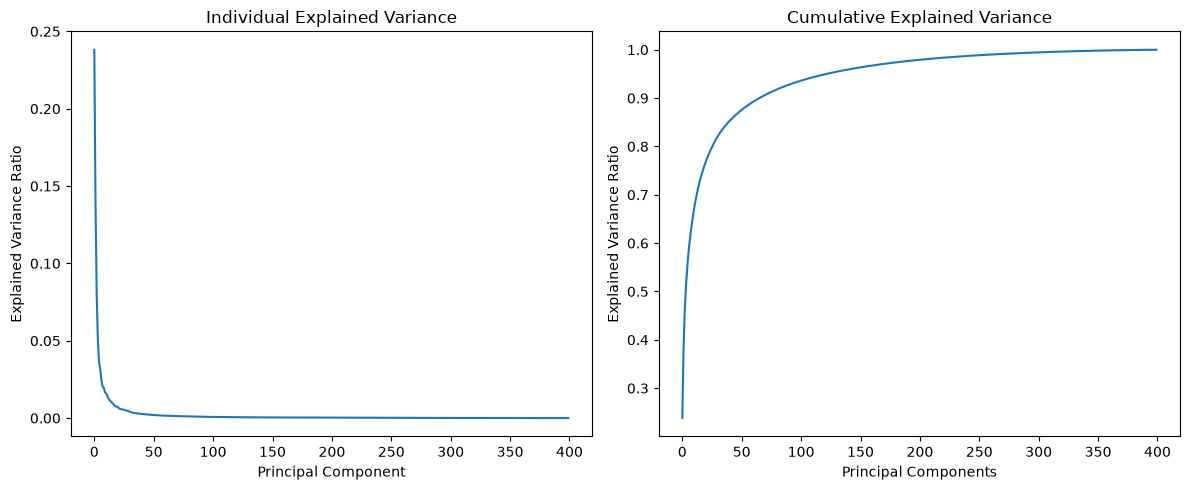

Number of components to explain 90% variance: 66
Number of components to explain 95% variance: 123
Number of components to explain 99% variance: 260


In [ ]:
from sklearn.decomposition import PCA

pca_full = PCA(svd_solver='full', n_components=None, random_state=42).fit(X)

individual_ev = pca_full.explained_variance_ratio_
cumulative_ev = np.cumsum(individual_ev)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(individual_ev)
axes[0].set_title('Individual Explained Variance')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')

axes[1].plot(cumulative_ev)
axes[1].set_xlabel('Principal Components')
axes[1].set_ylabel('Explained Variance Ratio')
axes[1].set_title('Cumulative Explained Variance')
plt.tight_layout()
plt.show()

n_components_90 = np.argmax(cumulative_ev >= 0.9) + 1
print(f'Number of components to explain 90% variance: {n_components_90}')

n_components_95 = np.argmax(cumulative_ev >= 0.95) + 1
print(f'Number of components to explain 95% variance: {n_components_95}')

n_components_99 = np.argmax(cumulative_ev >= 0.99) + 1
print(f'Number of components to explain 99% variance: {n_components_99}')

## Task 3: Image Compression and Reconstruction Analysis

This code cell takes an image from the 5 first subjects, compresses and reconstructs the image with each k value: 10, 50, 100, 200, 300. Transform compresses the image into k values, and then inverse_transform transforms them back to pixels. Then I plotted the images into a graph. Finally I calculated the MSE of the original X values and the reconstructed data. This calculation was then used in a in a graph to display each subjects MSE values.

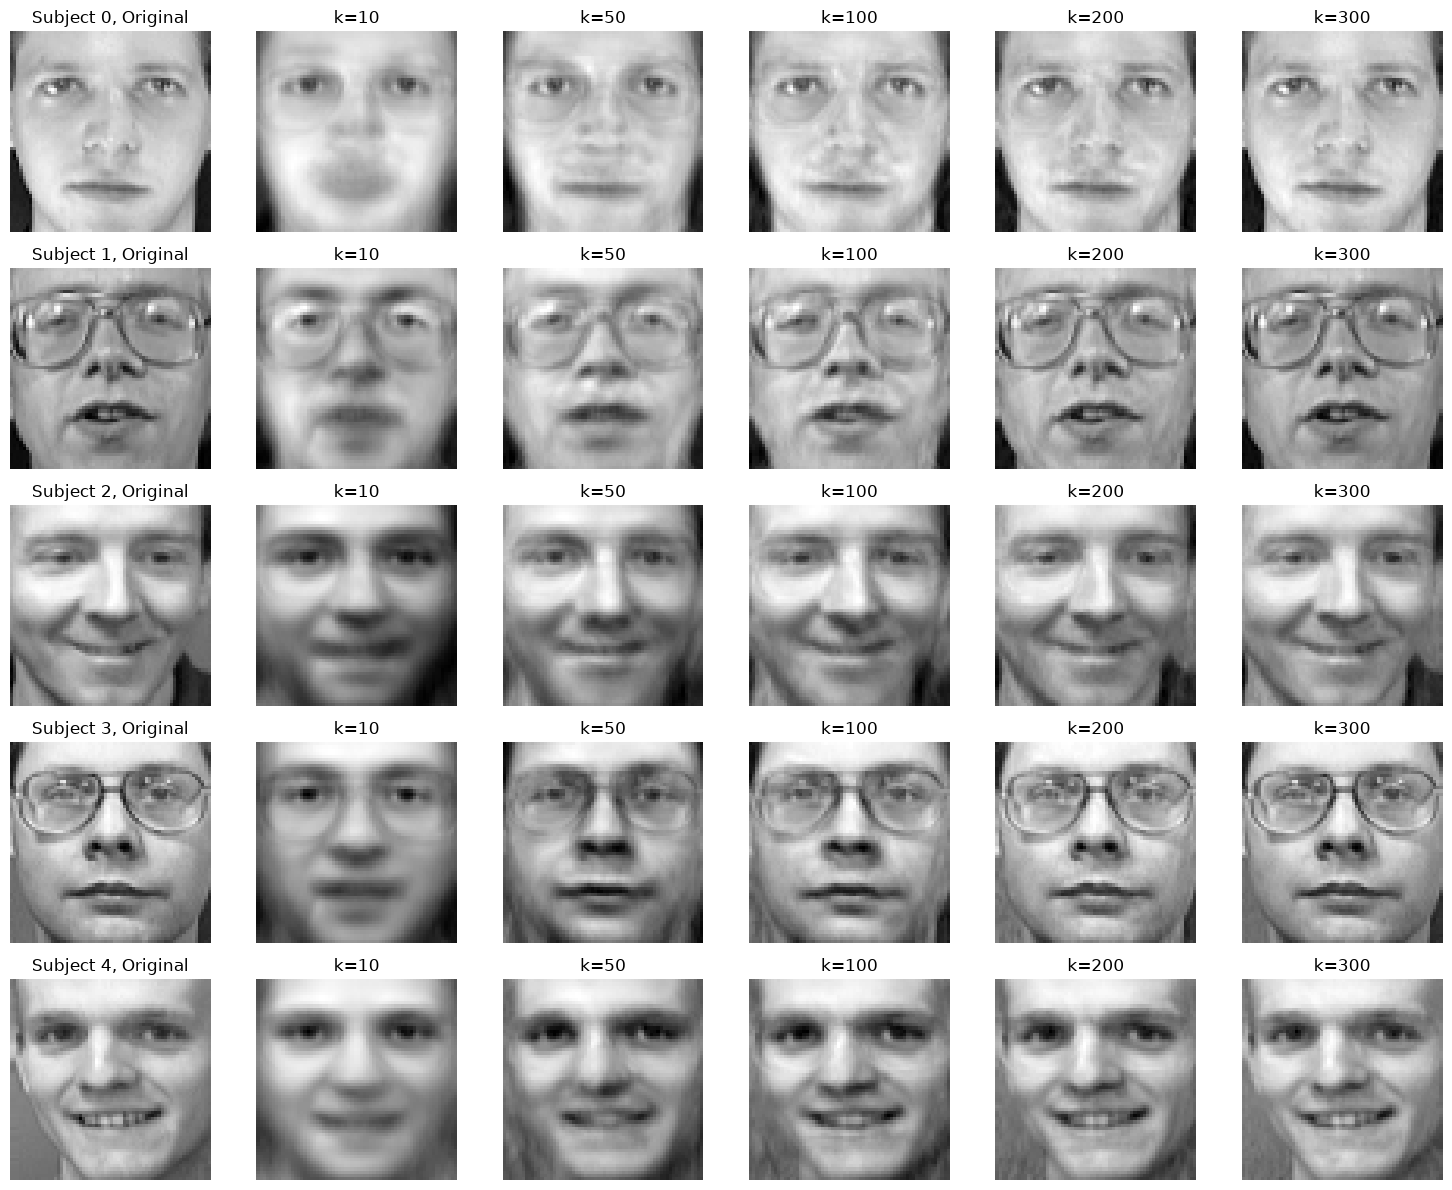

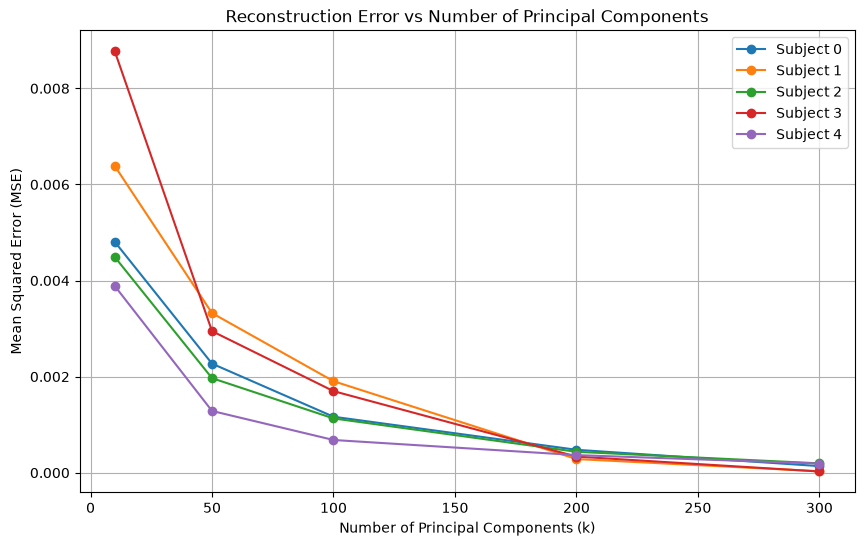

In [ ]:
sample_idx = [0, 10, 20, 30, 40]
ks = [10, 50, 100, 200, 300]

mse = {}
fig, axes = plt.subplots(len(sample_idx), len(ks) + 1, figsize=(15, 12))
for idx in sample_idx:
    ax = axes[sample_idx.index(idx), 0]
    ax.imshow(images[idx].reshape(64, 64), cmap='gray')
    ax.set_title(f'Subject {int(idx / 10)}, Original')
    ax.axis('off')
    for k in ks:
        pca = PCA(n_components=k, random_state=42).fit(X)
        X_reduced = pca.transform(X)
        X_reconstructed = pca.inverse_transform(X_reduced)
        mse[(idx, k)] = np.mean((X[idx] - X_reconstructed[idx]) ** 2)

        ax = axes[sample_idx.index(idx), ks.index(k) + 1]
        ax.imshow(X_reconstructed[idx].reshape(64, 64), cmap='gray')
        ax.set_title(f'k={k}')
        ax.axis('off')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
for idx in sample_idx:
    mse_values = [mse[(idx, k)] for k in ks]
    plt.plot(ks, mse_values, marker='o', label=f'Subject {int(idx / 10)}')
plt.title('Reconstruction Error vs Number of Principal Components')
plt.xlabel('Number of Principal Components (k)')
plt.ylabel('Mean Squared Error (MSE)')
plt.legend()
plt.grid()


## Task 4: Visualization of "Eigenfaces"

This code cell takes the first 15 eigenvectors or the principal components. It uses the components_ value and cycles through the first 15. I also displayed on each eigenvector the percentage of total variance associated with each component.

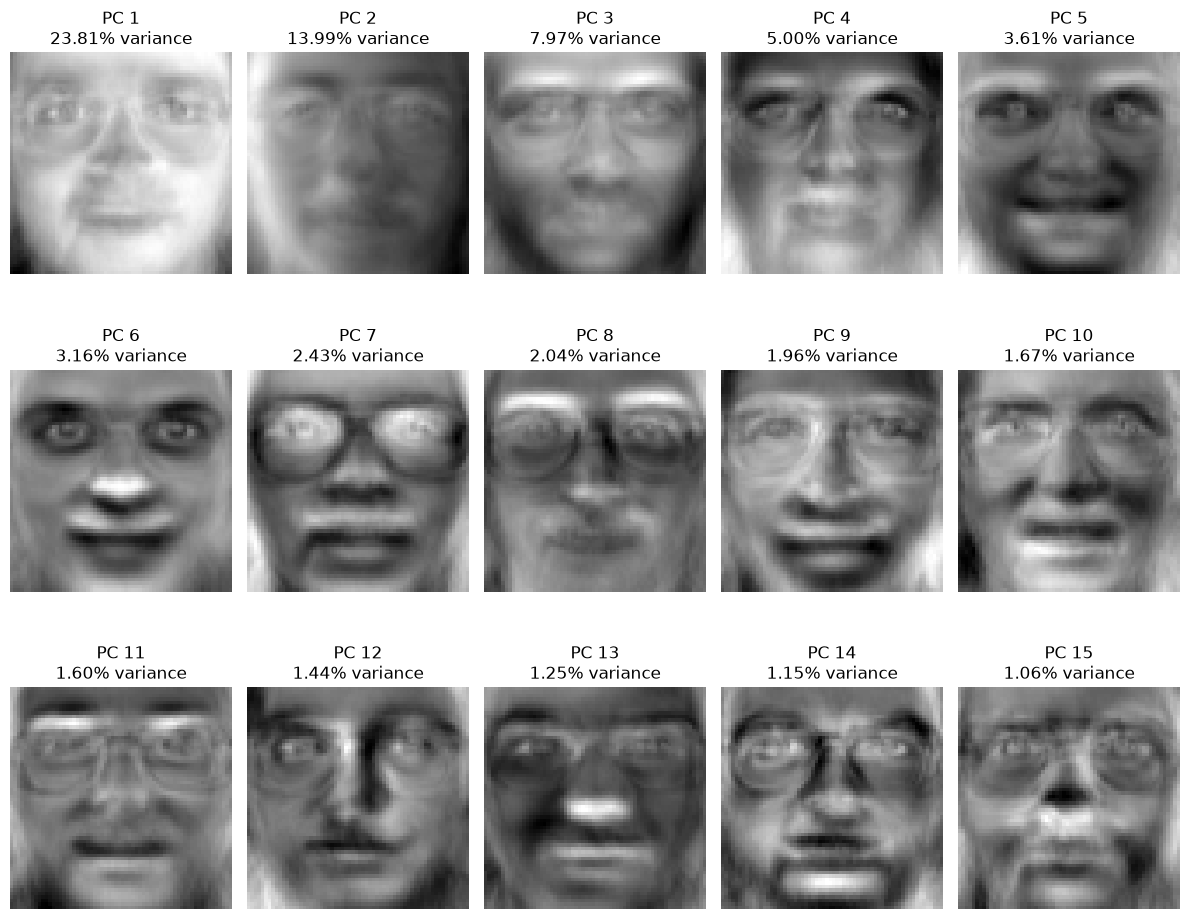

In [ ]:
ev = pca_full.components_
fig, axes = plt.subplots(3, 5, figsize=(12, 10))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(pca_full.components_[i].reshape(64, 64), cmap="gray")
    ax.set_title(f"PC {i + 1}\n{individual_ev[i] * 100:.2f}% variance")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Task 5: Classification Baseline — Raw vs. PCA-Reduced Features (Linear Model)

I started this cell by importing necessary modules and creating a function. I use this function to print bar graphs for this cell and others in other cells to demonstrate testing accuract and speed for different models. I then make test and training splits using stratify so each subject is equally represented. I then make a linear regression model on the the 4096 dimension pixel values, and another linear regression model using a PCA reduced vectors which only uses the amount of components to reach a cumulative 95% variance. I timed the fitting of both models and plotted them using my bar_plot function.

The results show that reducing components to where there is still a 95% cumulative decreases testing time by a decent margin and very lightly decreases accuracy.

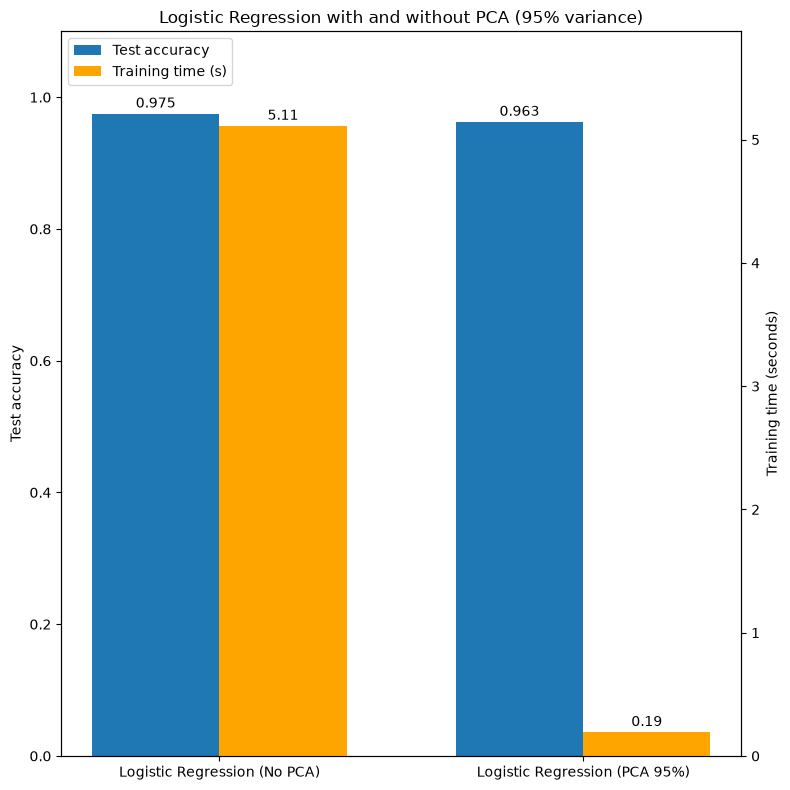

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import time

def bar_plot(values, title):
    models = list(values['Model'])
    n = len(models)
    x = np.arange(n)
    width = 0.35
    fig, ax1 = plt.subplots(figsize=(max(8, 3 * n), 8))
    acc_bars = ax1.bar(x - width / 2, values['Accuracy'], width, label="Test accuracy")
    ax1.set_ylabel("Test accuracy")
    ax1.set_ylim(0, 1.1)
    ax2 = ax1.twinx()
    time_bars = ax2.bar(x + width / 2, values['Time'], width, color='orange', label="Training time (s)")
    ax2.set_ylabel("Training time (seconds)")
    ax2.set_ylim(0, max(values['Time']) * 1.15)
    ax1.bar_label(acc_bars, fmt="%.3f", padding=2)
    ax2.bar_label(time_bars, fmt="%.2f", padding=2)
    ax1.set_xticks(x)
    ax1.set_xticklabels(models)
    ax1.set_title(title)
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="upper left")
    plt.tight_layout()
    plt.show()

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

lr = LogisticRegression(max_iter=1000, random_state=42)
time_start = time.time()
lr.fit(X_train, y_train)
time_score = time.time() - time_start
y_pred = lr.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)

values = {
    'Model': ['Logistic Regression (No PCA)'],
    'Accuracy': [test_accuracy],
    'Time': [time_score]
}

pca_95 = PCA(n_components=0.95, random_state=42)
time_start = time.time()
X_train_pca = pca_95.fit_transform(X_train)
X_test_pca = pca_95.transform(X_test)

lr_pca = LogisticRegression(max_iter=1000, random_state=42)
lr_pca.fit(X_train_pca, y_train)
time_score_pca = time.time() - time_start
y_pred_pca = lr_pca.predict(X_test_pca)
accuracy_pca = accuracy_score(y_test, y_pred_pca)

values['Model'].append('Logistic Regression (PCA 95%)')
values['Accuracy'].append(accuracy_pca)
values['Time'].append(time_score_pca)

bar_plot(values, "Logistic Regression with and without PCA (95% variance)")

## Task 6: Non-Linear Classification (Kernel SVM)

First I imported more modules to create an SVC model and a confusion matrix. I then created another another model of a Kernel SVM using the 95% variance PCA training data I created earlier. I added the results to the values data structure for later graphing. Finally I plot all the subjects into a confusion matrix.

SVC (PCA 95%) Test Accuracy: 0.9375, Training Time: 0.0225 seconds


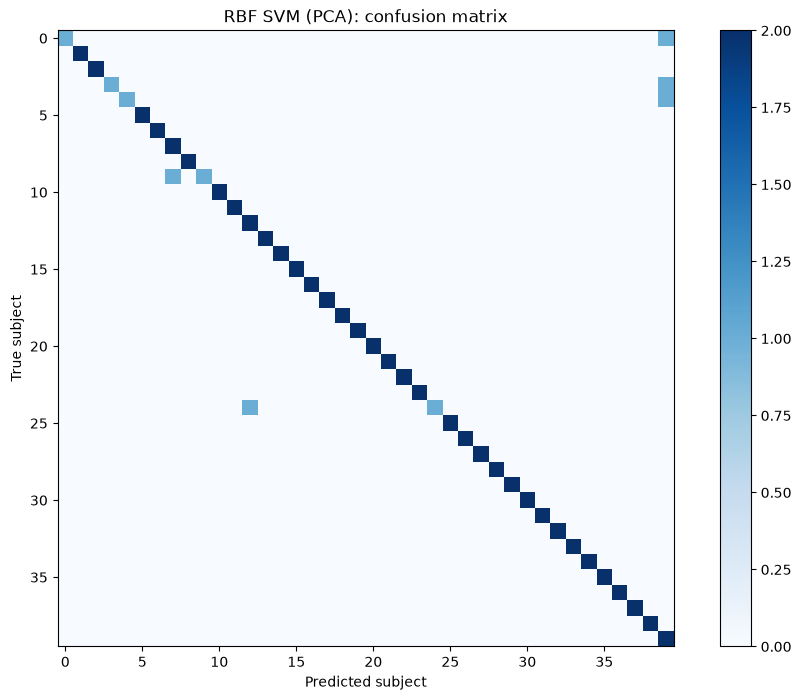

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix

svc = SVC(kernel='rbf', random_state=42)
time_start = time.time()
svc.fit(X_train_pca, y_train)
time_score_svc = time.time() - time_start
pred_svc = svc.predict(X_test_pca)
svc_accuracy = accuracy_score(y_test, pred_svc)

values['Model'].append('SVC (PCA 95%)')
values['Accuracy'].append(svc_accuracy)
values['Time'].append(time_score_svc)

print(f"SVC (PCA 95%) Test Accuracy: {svc_accuracy:.4f}, Training Time: {time_score_svc:.4f} seconds")

plt.figure(figsize=(12, 8))
plt.imshow(confusion_matrix(y_test, pred_svc, labels=np.arange(len(np.unique(y)))), cmap="Blues")
plt.colorbar()
plt.title("RBF SVM (PCA): confusion matrix")
plt.xlabel("Predicted subject")
plt.ylabel("True subject")
plt.show()

## Task 7: Ensemble Classification on PCA Features

This cell creates a soft voting classifier with three classifers, a poly SVC, kernel SVC, and a random forest. I then fit the the model using the PCA reduced data and record the accuracy and test speed.

In [ ]:
from sklearn.ensemble import VotingClassifier, RandomForestClassifier

ensemble = VotingClassifier(
    estimators=[
        ("poly_svm", SVC(kernel="poly", degree=2, probability=True, random_state=42)),
        ("rbf_svm", SVC(kernel="rbf", probability=True, random_state=42)),
        ("rf", RandomForestClassifier(n_estimators=100, random_state=42)),
    ],
    voting="soft")

time_start = time.time()
ensemble.fit(X_train_pca, y_train)
time_score_ensemble = time.time() - time_start
pred_ensemble = ensemble.predict(X_test_pca)
ensemble_accuracy = accuracy_score(y_test, pred_ensemble)

values['Model'].append('Ensemble (PCA 95%)')
values['Accuracy'].append(ensemble_accuracy)
values['Time'].append(time_score_ensemble)

pd.DataFrame(values).sort_values(by='Accuracy', ascending=False).reset_index(drop=True)

c:\Users\kevin\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\kevin\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,Accuracy,Time
0,Logistic Regression (No PCA),0.9750,5.111774
1,Logistic Regression (PCA 95%),0.9625,0.193153
2,Ensemble (PCA 95%),0.9500,0.591618
3,SVC (PCA 95%),0.9375,0.022513


## Task 8: Comprehensive Comparative Evaluation

Finally I used the values data and bar_plot function to plot test accuracy and speed for Logistic Regression (No PCA), Logistic Regression (PCA 95%), SVC (95%), and Ensamble (95%). The data reinforces what I was stating before that the models trained on PCA reduced vectors were much faster while very slightly less accurate. The PCA reduced SVM model was by far the fastest while being 3.7% less accurate than the most accurate model. The PCA reduced

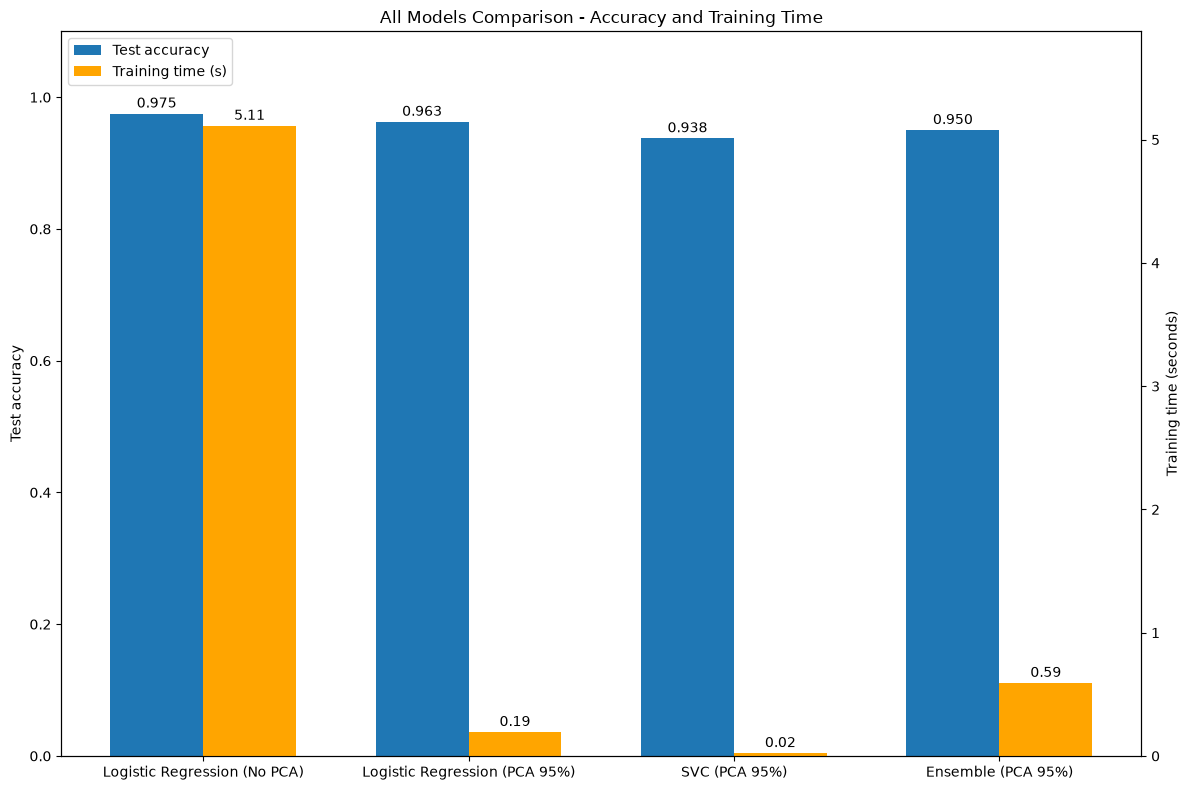

In [ ]:
bar_plot(values, "All Models Comparison - Accuracy and Training Time")